Equations of Motion 

$$
\begin{aligned}
\dot x &= v_x \\
\dot y &= v_y \\
\dot v_x &= 2 v_y + x - \frac{(1 - \mu)(x + \mu)}{r_1^3} - \frac{\mu (x - 1 + \mu)}{r_2^3} \\
\dot v_y &= -2 v_x + y - \frac{(1-\mu) y}{r_1^3} - \frac{\mu y}{r_2^3}
\end{aligned}
$$

where, 

$$
\begin{aligned}
\mu &= \frac{m_M}{m_E + m_M}\\
r_1 &= \sqrt{(x + \mu)^2 + y^2} \\
r_2 &= \sqrt{(x - 1 + \mu)^2 + y^2} 
\end{aligned}
$$

Converting to Matrix form

$$
u = 
\begin{bmatrix}
x \\
y \\
v_x \\
v_y \\
\end{bmatrix}
$$

$$
A = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{r_1^3}-\frac{\mu}{r_2^3} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{r_1^3}-\frac{\mu}{r_2^3} & -2 & 0\\
\end{bmatrix}
$$

$$
b = 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{r_2^3} - \frac{1}{r_1^3}) \\
0 \\
\end{bmatrix}
$$

$$
\dot u = A u + b
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Below is $f(u, t)$ defined with the necessary constants

In [2]:
from Helpers.constants import *

def f_spacecraft(u, t):
    """The dynamics of the spacecraft: returns u_dot = f(u, t).
    
    Parameters
    ----------
    u : ndarray
        The current state [x, y, v_x, v_y]
    t : float
        The current time (unused here — the system is autonomous — but kept in
        the signature so that every marcher can call f the same way)

    Returns
    -------
    u_dot : ndarray
        The four components of du/dt
    """

    r1 = np.sqrt((u[0] + MU)**2 + u[1]**2)
    r2 = np.sqrt((u[0] - 1 + MU)**2 + u[1]**2)

    return np.array([
        u[2],
        u[3],
        (1 - (1 - MU)/r1**3 - MU/r2**3)*u[0] + 2*u[3] + MU*(1 - MU)*(1/r2**3 - 1/r1**3),
        (1 - (1 - MU)/(r1**3) - MU/r2**3)*u[1] - 2*u[2]
    ])

Below is the work and code to get evaluate stiffness.

$$
\dot u = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{r_1^3}-\frac{\mu}{r_2^3} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{r_1^3}-\frac{\mu}{r_2^3} & -2 & 0\\
\end{bmatrix}
u + 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{r_2^3} - \frac{1}{r_1^3}) \\
0 \\
\end{bmatrix}
$$

Substituting in $r_1$ and $r_2$

$$
\dot u = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}-\frac{\mu}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}-\frac{\mu}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} & -2 & 0\\
\end{bmatrix}
u + 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} - \frac{1}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}) \\
0 \\
\end{bmatrix}
$$

Now the Jacobian can be evaluated

With the Jacobian, we can evaluate stiffness given a reference state $\bar u$ where $f(u) =  0$

Given the equations of motion, this means that the velocity componenets of the reference state must be 0. $\bar v_x, \bar v_y = 0$.

Then if we make it so $r_1$ and $r_2$ are equivalent, then $f = 0$ will be satisfied. (Credit to AI for this idea).

Setting $r_1 = r_2$ gives

$
\sqrt{(x + \mu)^2 + y^2} = \sqrt{(x - 1 + \mu)^2 + y^2} \\
(x + \mu)^2 = (x - 1 + \mu)^2 \\
(x + \mu) = -(x - 1 + \mu) \\
\bar x = \frac{1}{2} - \mu
$

To get the y value we look at the $\bar v_x$ equation where when $r_1 = r_2$, the equation simplifies to:

$
(1 - \frac{1 - \mu}{r_1^3} - \frac{\mu}{r_2^3}) x = 0 \\
(1 - \frac{1}{r_1^3}) x = 0
$

This means $(1 - \frac{1}{r_1^3})$ must equal $0$ for $f$ to be $0$. That then means $\bar r_1, \bar r_2$ must equal $1$

Solving either $r_1$ or $r_2$ for $\bar y$ given $\bar x$ and knowing they must equal $1$ gives

$
\sqrt((\bar x + \mu)^2 + y^2) = 1 \\
\frac{1}{4} + y^2 = 1 \\
\bar y = \frac{\sqrt 3}{2}
$



In [3]:
x_bar = 0.5 - MU
y_bar = np.sqrt(3)/2

u_bar = np.array([x_bar, y_bar, 0, 0])

# Checking if u_bar satisifies f(u_bar) = 0
print(f_spacecraft(u_bar, 0))

[ 0.00000000e+00  0.00000000e+00 -1.50637578e-16 -2.67411999e-16]


Now the Jacobian can be evaluated at $\bar u$. Taking the eigenvalues of the Jacobian and calculating the stiffness ratio.

In [4]:
from Helpers.jacobian import *

J = jacobian(u_bar, MU)

eigenvals, eigenvects = np.linalg.eig(J)

stiffness_ratio_mag = np.max(np.abs(eigenvals))/np.min(np.abs(eigenvals))

print(f'Stiffness Ratio using Magnitude of Complex Numbers: {stiffness_ratio_mag}')

print('\nEigenvalues:')
for eigenval in eigenvals:
    print(eigenval)

Stiffness Ratio using Magnitude of Complex Numbers: 3.2003033355781163

Eigenvalues:
(1.817990202823694e-15+0.9544880265847181j)
(1.817990202823694e-15-0.9544880265847181j)
(-1.444157293750692e-15+0.29824923655628893j)
(-1.444157293750692e-15-0.29824923655628893j)


Since the eigenvalues ended up being complex numbers, we evaluated the stiffness ratio by taking the maximum and minimum of the magnitudes of all the eigenvalues (credit to AI for that idea). 

Since the ratio is not much, much larger than 1, the IVP is not stiff. Therefore, explicit methods like those in the AB family, or RK4 can be used.

We will use RK4 because the eigenvalues evaluated for this IVP are more complex than real. RK4 gives better stability for the complex plane.

From Lecture Notes

$$
u_{k+1} = u_k + \frac{\Delta t}{6}(y_1 + 2y_2 + 2y_3 + y_4)\\
y_1 = f(u_k, t_k) \\
y_2 = f(u_k + \frac{1}{2}\Delta ty_1, t_k + \frac{1}{2}\Delta t) \\
y_3 = f(u_k + \frac{1}{2}\Delta ty_2, t_k + \frac{1}{2}\Delta t) \\ 
y_4 = f(u_k + \Delta t y_3, t_k + \Delta t) \\
$$

$R(w)$ of RK4 from Lecture notes:
$$
1 + w + \frac{1}{2} w^2 + \frac{1}{6} w^3 + \frac{1}{24} w^4
$$


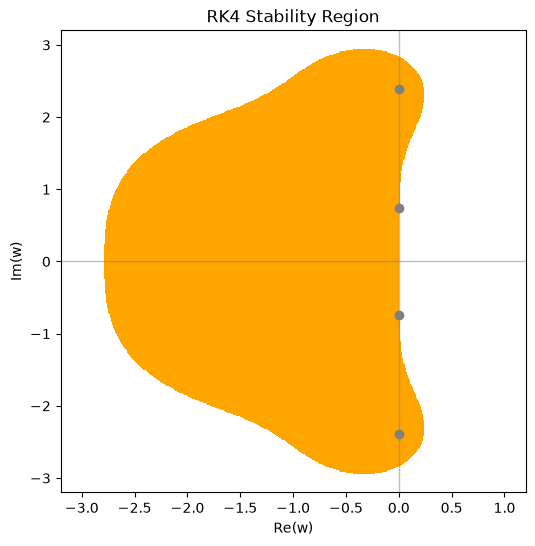

In [5]:
x, y = np.meshgrid(np.linspace(-3.2, 1.2, 401), np.linspace(-3.2, 3.2, 401)) # x = Re(w), y = Im(w)

dt_lam = x + 1j * y # w

amp = np.abs(1 + dt_lam + (1/2)*dt_lam**2 + (1/6)*dt_lam**3 + (1/24)*dt_lam**4)
stable = amp < 1

fig2 = plt.figure(figsize=(6, 6))
ax21 = fig2.add_subplot(111)

ax21.contourf(x, y, stable, levels=[0.5, 1.5], colors='ORANGE')
ax21.set_title('RK4 Stability Region')
ax21.set_xlabel('Re(w)')
ax21.set_ylabel('Im(w)')
ax21.axhline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)
ax21.axvline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)

dt_test = 2.5 # s

ax21.scatter(dt_test * eigenvals.real, dt_test * eigenvals.imag, color='GREY')

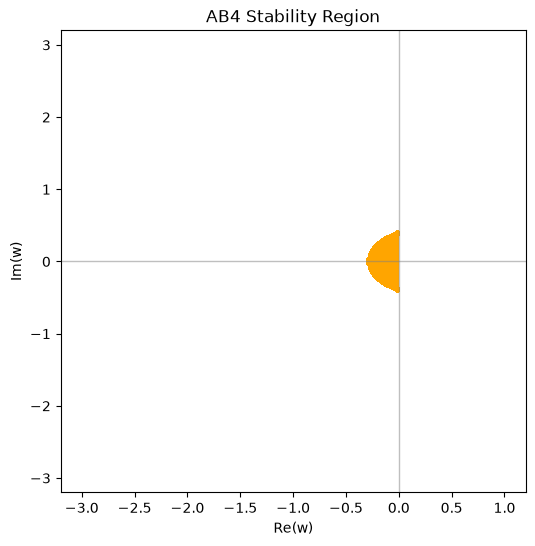

In [6]:
x, y = np.meshgrid(np.linspace(-3.2, 1.2, 401), np.linspace(-3.2, 3.2, 401)) # x = Re(w), y = Im(w)

dt_lam = x + 1j * y # w

ab4_coeffs = lambda w : [1, -(1+(55/24)*w), (59/24)*w, -(37/24)*w, (3/8)*w]

amp = np.array([[np.max(np.abs(np.roots(ab4_coeffs(w)))) for w in row] for row in dt_lam])

stable = amp < 1

fig2 = plt.figure(figsize=(6, 6))
ax21 = fig2.add_subplot(111)

ax21.contourf(x, y, stable, levels=[0.5, 1.5], colors='ORANGE')
ax21.set_title('AB4 Stability Region')
ax21.set_xlabel('Re(w)')
ax21.set_ylabel('Im(w)')
ax21.axhline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)
ax21.axvline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)

#ax21.scatter(eigenvals.real, eigenvals.imag, color='GREY')

Comparing the stability regions show how AB4, a comparable method as both of same order and both are explicit, is not stable enough to accurately use for this IVP. The RK4 method gives greater stability in the imaginary axis which is necessary for this problem

In [7]:
# INITIAL CONDITIONS

delta_v = 3.14 # km/s
phi = 4.12 # rad

x_0 = -MU + R_0_ND*np.cos(phi)
y_0 = R_0_ND*np.sin(phi)

v_C = np.sqrt((1 - MU)/R_0_ND) + delta_v/V

vx_0 = -v_C*np.sin(phi) + y_0
vy_0 = v_C*np.cos(phi) - (x_0 + MU)

u_start_ND = np.array([x_0, y_0, vx_0, vy_0])

#t_f = 7.5*24*60*60 # s
#t_f_ND = t_f / T

t_f_ND = 2
t_f = 2*T


Test convergence against a small $\Delta t$ to confirm the expected convergence rate of $\Delta t^4$

<>:25: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:26: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
<>:25: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:26: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
/tmp/ipykernel_155749/1726610353.py:25: SyntaxWarning: "\D" is an invalid es

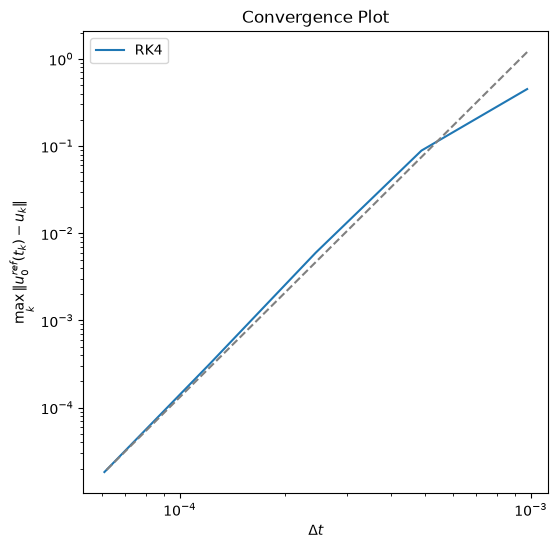

In [8]:
from Helpers.rk4 import rk4

dt_ref_ND = t_f_ND/2**17
dt_ref = dt_ref_ND * T

dt_list_ND = np.array([t_f_ND/2**11, t_f_ND/2**12, t_f_ND/2**13, t_f_ND/2**14, t_f_ND/2**15])
dt_list = dt_list_ND * T

u_ref_ND, times_ref_ND = rk4(f_spacecraft, u_start_ND, t_f_ND, dt_ref_ND)

def global_error(u, times, dt_ND, dimension):
    '''Dimension is an integer 0-3 representing which of x, y, vx, vy should be compared'''
    return np.abs(u[:, dimension] - u_ref_ND[::(int(round(dt_ND/dt_ref_ND))), dimension]).max()

error_list_ND = []

for dt_ND in dt_list_ND:
    u, times = rk4(f_spacecraft, u_start_ND, t_f_ND, dt_ND)
    error_list_ND.append(global_error(u, times, dt_ND, 0))

fig4 = plt.figure(figsize=(6, 6))
ax41 = fig4.add_subplot(111)

ax41.set_title(f'Convergence Plot')
ax41.set_xlabel(f'$\Delta t$')
ax41.set_ylabel(f'$\max_k \| u_0^{{ref}}(t_k) - u_k \|$')
ax41.set_xscale('log')
ax41.set_yscale('log')

ax41.plot(dt_list_ND, error_list_ND, label='RK4')
ax41.plot(dt_list_ND, error_list_ND[-1] * (dt_list_ND / dt_list_ND[-1])**4, ls='--', color='GREY')

ax41.legend()